# Auckland comparé aux autres équipes

Le notebook 02 étudie la zone 14 sur quatre matchs d'Auckland FC, sans point de comparaison : on ne peut pas savoir si Auckland utilise cette zone plus ou moins que les autres équipes. L'open data de SkillCorner contient vingt matchs de la saison, dont sept d'Auckland. On applique la fonction `bilan_match()` du notebook 02 aux deux équipes de chaque match, puis on compare Auckland aux autres équipes. L'interprétation des résultats est présentée dans la synthèse (section 8).

## 1. Chargement des vingt matchs

Ces matchs ne sont pas tous dans notre espace de stockage S3 : on les lit directement sur le dépôt GitHub de SkillCorner avec `charger_match()` (`src/donnees.py`). La version des fichiers est fixée sur un état du dépôt, pour que les résultats ne changent pas si SkillCorner modifie ses données.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

#on indique le chemin du dossier src
if Path('src').exists():
    sys.path.append('src')
else:
    sys.path.append('../src')

from donnees import liste_matchs, charger_match
from fonctions_comparaison import bilan_equipe, test_permutation

id_auckland = 4177
matchs = {id_match: charger_match(id_match) for id_match in liste_matchs()}
print('Matchs chargés :', len(matchs))

Matchs chargés : 20


Les coordonnées sont exprimées dans le sens d'attaque de l'équipe qui a le ballon (notebook 02). On le vérifie sur les vingt matchs : les tirs doivent presque tous être situés du côté x > 0, à chaque mi-temps.

In [2]:
tirs = pd.concat([ev.loc[(ev['event_type'] == 'player_possession') & (ev['end_type'] == 'shot'), ['period', 'x_end']]
                  for infos, ev in matchs.values()])
tirs.groupby('period')['x_end'].agg(nombre_de_tirs='size', part_x_positif=lambda x: (x > 0).mean()).round(3)

,nombre_de_tirs,part_x_positif
period,,
1,233,1.000
2,293,0.997


## 2. Auckland comparé aux autres équipes

Pour chaque équipe et chaque match, `bilan_equipe()` reprend les comptages de `bilan_match()` et les rapporte au volume de jeu de l'équipe (part des passes et des tirs, actions pour 100 passes ou pour 100 courses), pour comparer des matchs de physionomies différentes. Elle ajoute la part des possessions terminées dans le dernier tiers adverse côté gauche et côté droit (colonne `channel_end` de SkillCorner). On obtient quarante lignes : sept pour Auckland, trente-trois pour les douze autres équipes.

Pour savoir si un écart entre Auckland et les autres équipes peut être dû au hasard, on utilise un test de permutation : si les deux groupes ne diffèrent pas, on peut échanger les étiquettes « Auckland » et « autres » ; on les mélange 10 000 fois et la p-valeur est la part des mélanges qui donnent un écart au moins aussi grand que l'écart observé. Avec sept matchs et plusieurs indicateurs testés, une p-valeur proche de 5 % reste un indice, pas une preuve.

In [3]:
lignes = []
for id_match, (infos, evenements) in matchs.items():
    for id_equipe in [infos['home_team']['id'], infos['away_team']['id']]:
        ligne = bilan_equipe(infos, evenements, id_equipe)
        ligne['groupe'] = 'Auckland' if id_equipe == id_auckland else 'Autres équipes'
        lignes.append(ligne)
tableau = pd.DataFrame(lignes)
print(tableau['groupe'].value_counts())

noms_indicateurs = {
    'part_passes_depuis_z14': 'Part des passes jouées depuis la zone 14',
    'passes_vers_z14_pour_100_passes': 'Passes reçues en zone 14 pour 100 passes',
    'part_tirs_depuis_z14': 'Part des tirs pris depuis la zone 14',
    'courses_vers_z14_pour_100_courses': 'Courses vers la zone 14 pour 100 courses',
    'courses_depuis_z14_pour_100_courses': 'Courses depuis la zone 14 pour 100 courses',
    'part_fins_cote_gauche': "Part des fins d'action côté gauche (dernier tiers)",
    'part_fins_cote_droit': "Part des fins d'action côté droit (dernier tiers)",
}
auckland = tableau[tableau['groupe'] == 'Auckland']
autres = tableau[tableau['groupe'] == 'Autres équipes']
comparaison = pd.DataFrame({
    'Auckland': auckland[list(noms_indicateurs)].mean(),
    'autres équipes': autres[list(noms_indicateurs)].mean(),
    'p-valeur': [test_permutation(auckland[v], autres[v]) for v in noms_indicateurs],
})
comparaison.rename(index=noms_indicateurs).round(3)

groupe
Autres équipes    33
Auckland           7
Name: count, dtype: int64


,Auckland,autres équipes,p-valeur
Part des passes jouées depuis la zone 14,0.031,0.028,0.706
Passes reçues en zone 14 pour 100 passes,1.763,1.853,0.805
Part des tirs pris depuis la zone 14,0.242,0.253,0.867
Courses vers la zone 14 pour 100 courses,4.982,6.283,0.135
Courses depuis la zone 14 pour 100 courses,9.375,6.941,0.027
Part des fins d'action côté gauche (dernier tiers),0.505,0.412,0.030
Part des fins d'action côté droit (dernier tiers),0.314,0.401,0.038


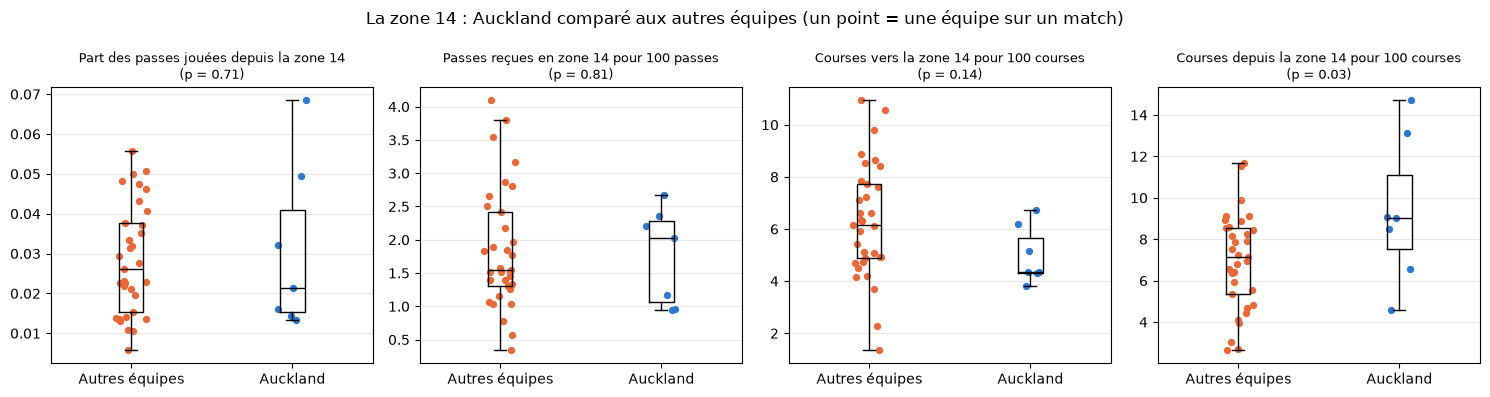

Matchs d'Auckland où les actions se terminent plus souvent à gauche qu'à droite : 6 sur 7


In [4]:
#une boîte par groupe, un point par équipe et par match
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
variables = ['part_passes_depuis_z14', 'passes_vers_z14_pour_100_passes',
             'courses_vers_z14_pour_100_courses', 'courses_depuis_z14_pour_100_courses']
generateur = np.random.default_rng(1)
for ax, variable in zip(axes, variables):
    groupes = [autres[variable], auckland[variable]]
    ax.boxplot(groupes, showfliers=False, medianprops={'color': 'black'})
    for position, valeurs, couleur in [(1, groupes[0], '#eb6834'), (2, groupes[1], '#2a78d6')]:
        ax.scatter(position + generateur.uniform(-0.1, 0.1, len(valeurs)), valeurs, color=couleur, s=18)
    ax.set_xticks([1, 2])
    ax.set_xticklabels(['Autres équipes', 'Auckland'])
    ax.set_title(noms_indicateurs[variable] + f"\n(p = {comparaison.loc[variable, 'p-valeur']:.2f})", fontsize=9)
    ax.grid(axis='y', alpha=0.3)
fig.suptitle('La zone 14 : Auckland comparé aux autres équipes (un point = une équipe sur un match)')
plt.tight_layout()
dossier_images = Path('images') if Path('images').exists() else Path('../images')
plt.savefig(dossier_images / 'comparaison_zone14_ligue.png', dpi=110, bbox_inches='tight')
plt.show()

print("Matchs d'Auckland où les actions se terminent plus souvent à gauche qu'à droite :",
      (auckland['part_fins_cote_gauche'] > auckland['part_fins_cote_droit']).sum(), 'sur', len(auckland))

## 3. Récapitulatif et limites

Les fonctions du notebook 02 sont appliquées sans modification aux vingt matchs de l'open data ; les sept matchs d'Auckland sont comparés aux trente-trois lignes des autres équipes avec des indicateurs rapportés au volume de jeu et un test de permutation. Limites : sept matchs seulement pour Auckland, des autres équipes observées sur un à quatre matchs chacune, plusieurs indicateurs testés à la fois, et deux équipes d'un même match qui s'influencent mutuellement.